# How the sources of risk change over time

The decomposition of [`03_strategy_decomposition`](03_strategy_decomposition.ipynb) in rolling windows, as Figure 1 of the paper does for two US portfolios: 60-month windows of monthly returns, and 252-day windows of daily returns. The factors are orthogonalized again inside each window, so the components add up to 100% in every window. Each point is the window that ends on that date.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl
from orthofactors.decomposition import rolling_window_regression
from orthofactors.plotting import set_style, factor_colors, plot_decomposition, DIVERGING

set_style()
Path('results').mkdir(exist_ok = True)
Path('docs').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

In [2]:
factors_daily = load_brazil_factors()[BRAZIL_FACTORS]
strategies_daily = load_brazil_strategies()
factors = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
strategies = to_monthly(strategies_daily).loc[MONTHLY_SAMPLE]

# Rolling decomposition, with the factors orthogonalized in each window
rolling_monthly = rolling_window_regression(strategies, factors, window_days = 60, orthogonalize = orthogonalize_swl)
rolling_daily = rolling_window_regression(strategies_daily, factors_daily, window_days = 252, orthogonalize = orthogonalize_swl)

for name, rolling in [('60-month', rolling_monthly), ('252-day', rolling_daily)]:
    gap = max((rolling[s][BRAZIL_FACTORS].sum(axis = 1) - rolling[s]['R2']).abs().max() for s in BRAZIL_STRATEGIES)
    print(f'{name} windows: {len(rolling)}, ending from {rolling.index[0]:%Y-%m-%d} to {rolling.index[-1]:%Y-%m-%d}; '
          f'largest gap between the sum of DR² and R²: {gap:.1e}')

60-month windows: 138, ending from 2015-01-31 to 2026-06-30; largest gap between the sum of DR² and R²: 3.0e-15
252-day windows: 3906, ending from 2011-01-04 to 2026-07-23; largest gap between the sum of DR² and R²: 9.5e-15


## 60-month windows

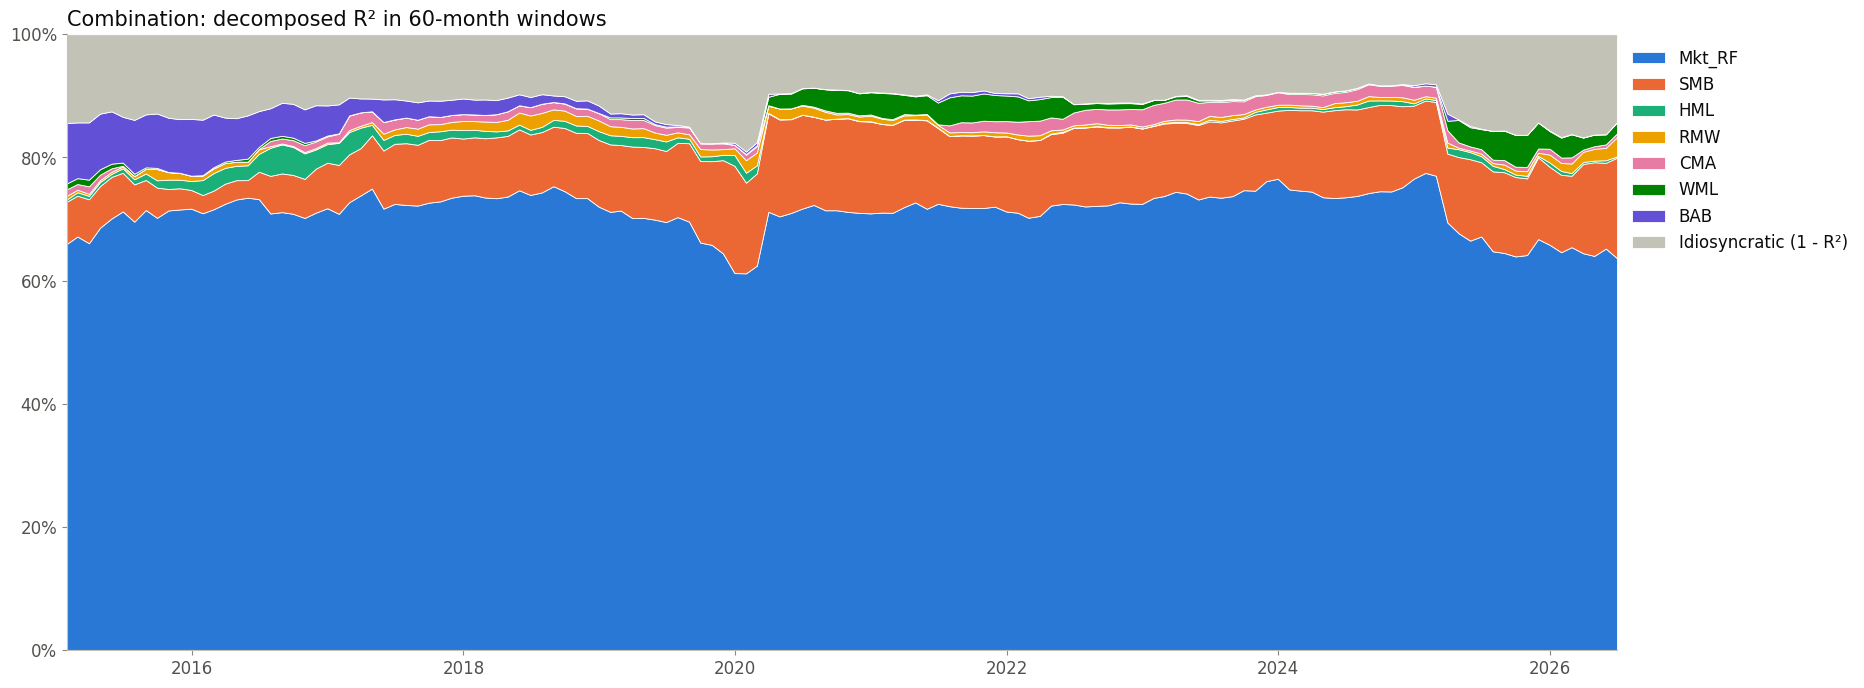

In [3]:
fig, ax = plt.subplots()
plot_decomposition(ax, rolling_monthly['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 60-month windows')
plt.show()

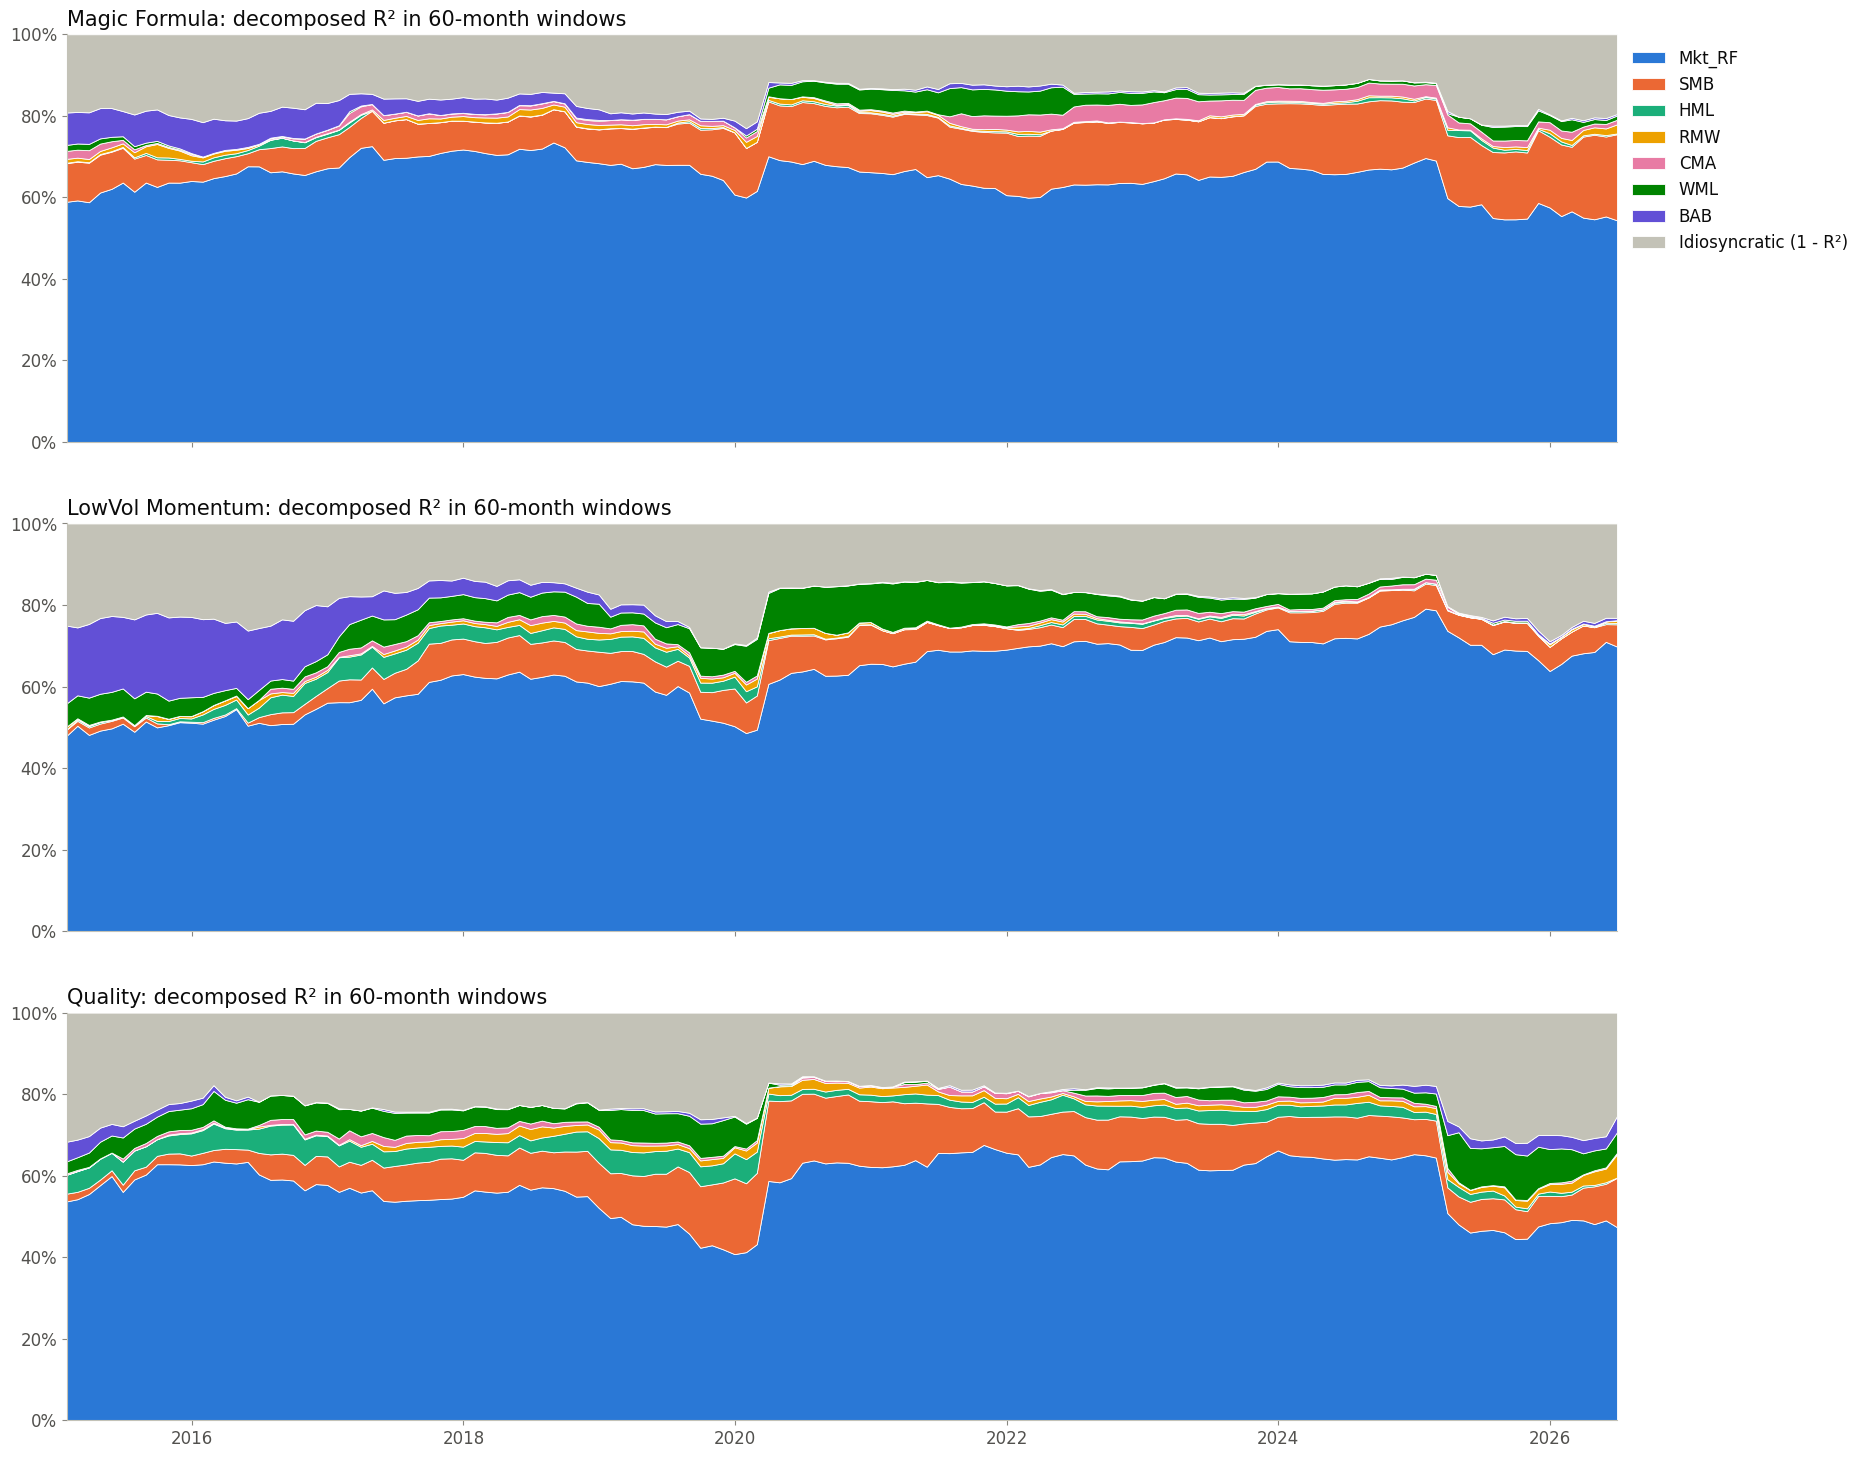

In [4]:
fig, axes = plt.subplots(3, 1, figsize = (20, 18), sharex = True)
for i, (ax, strategy) in enumerate(zip(axes, ['Magic Formula', 'LowVol Momentum', 'Quality'])):
    plot_decomposition(ax, rolling_monthly[strategy], BRAZIL_FACTORS, f'{strategy}: decomposed R² in 60-month windows')
    if i > 0:
        ax.get_legend().remove()
plt.show()

In [5]:
# First and last window, and the range over the windows, for the Combination
combination = rolling_monthly['Combination'][BRAZIL_FACTORS + ['idiosyncratic']]
pd.DataFrame({f'2010-02 to {combination.index[0]:%Y-%m}': combination.iloc[0],
              f'{combination.index[-1] - pd.DateOffset(months = 59):%Y-%m} to {combination.index[-1]:%Y-%m}': combination.iloc[-1],
              'Lowest': combination.min(), 'Highest': combination.max()}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
2010-02 to 2015-01,66.0%,6.8%,0.4%,0.6%,1.1%,1.0%,9.8%,14.4%
2021-07 to 2026-06,63.7%,16.3%,0.2%,3.2%,0.6%,1.8%,0.1%,14.3%
Lowest,61.2%,2.9%,0.0%,0.1%,0.0%,0.0%,0.0%,7.9%
Highest,77.5%,17.4%,4.7%,3.2%,3.3%,5.2%,9.8%,19.0%


In [6]:
# Average of each component over the 60-month windows, by strategy
pd.DataFrame({s: rolling_monthly[s][BRAZIL_FACTORS + ['idiosyncratic']].mean() for s in BRAZIL_STRATEGIES}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Combination,71.2%,11.1%,0.9%,0.9%,1.2%,1.2%,1.8%,11.7%
Magic Formula,65.1%,12.1%,0.4%,0.7%,1.8%,1.7%,2.2%,16.0%
LowVol Momentum,63.4%,6.0%,1.5%,0.6%,0.6%,5.1%,3.9%,19.0%
Quality,57.8%,9.7%,3.3%,1.3%,0.9%,4.2%,0.8%,22.0%


The market is always the largest source, with 61% to 78% of the variance of the Combination. What changed over time is the second source: in the first window (2010–2015), BAB explained 10% and size 7%, and in the last one (2021–2026) size explains 16% and BAB nothing. Value, profitability, investment and momentum never explained more than about 5%, and the idiosyncratic share stayed between 8% and 19%. The sleeves follow the same pattern, with more momentum in LowVol Momentum (5.1% on average) and in Quality (4.2%).

## 252-day windows

Daily windows react faster. The white dashed lines mark the start of the 2014–2016 recession (second quarter of 2014, as dated by CODACE), the COVID-19 crash of March 2020 and the first increase of the SELIC rate in March 2021, at the start of a cycle that took it from 2% to 13.75%.

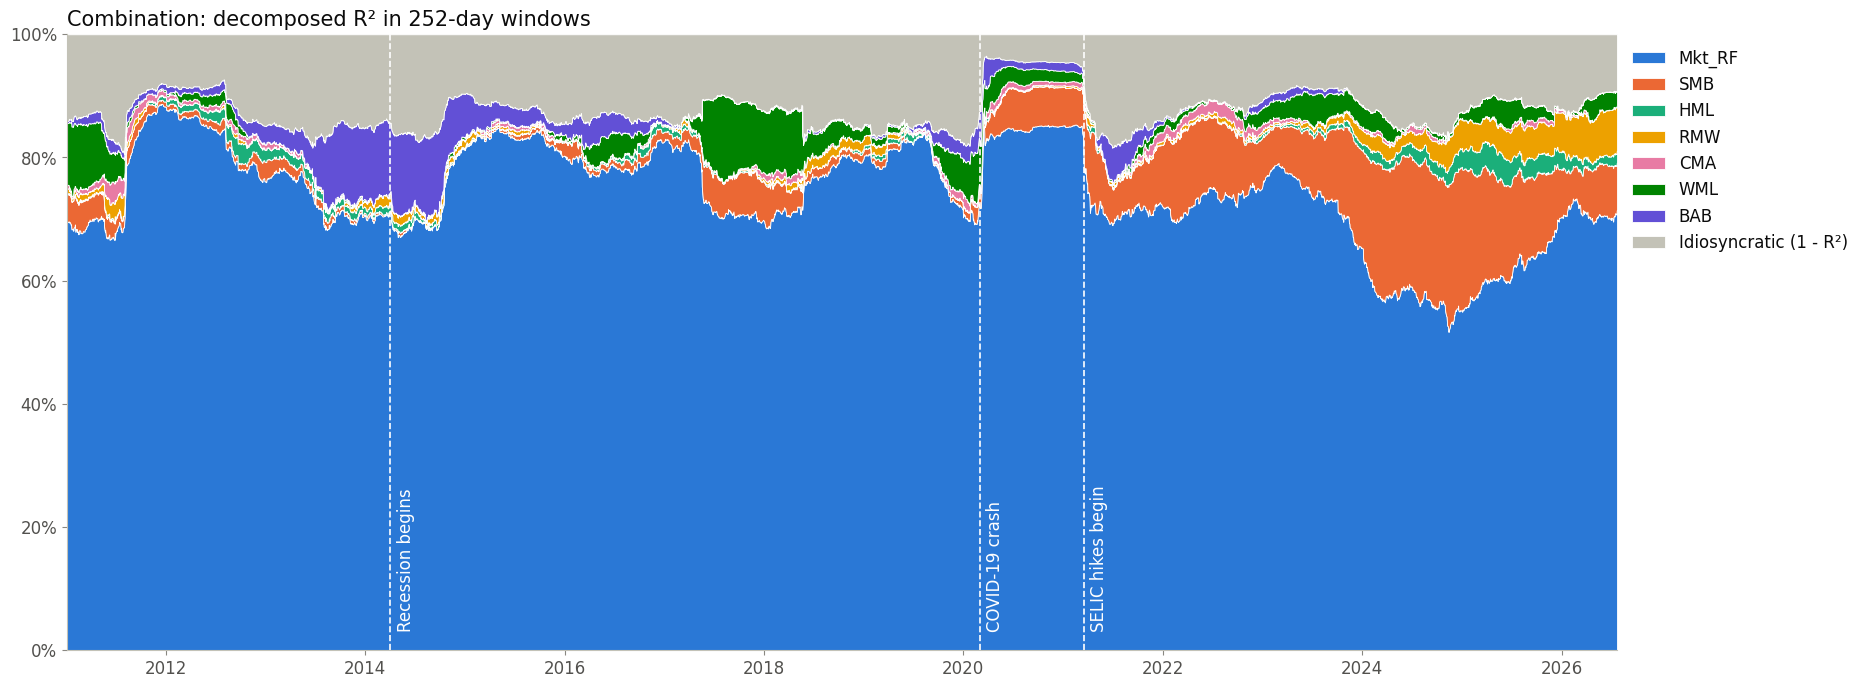

In [7]:
events = {'Recession begins': '2014-04-01', 'COVID-19 crash': '2020-03-01', 'SELIC hikes begin': '2021-03-17'}

fig, ax = plt.subplots()
plot_decomposition(ax, rolling_daily['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 252-day windows')
for label, day in events.items():
    ax.axvline(pd.Timestamp(day), color = '#ffffff', linestyle = '--', linewidth = 1.2)
    ax.text(pd.Timestamp(day) + pd.Timedelta(days = 25), 0.03, label, rotation = 90, ha = 'left', va = 'bottom',
            fontsize = 12, color = '#ffffff')
fig.savefig('docs/combination_rolling_decomposition.png', dpi = 100, bbox_inches = 'tight')
plt.show()

In [8]:
# Average of the daily windows that end in each year
yearly = rolling_daily['Combination'][BRAZIL_FACTORS + ['idiosyncratic']].groupby(rolling_daily.index.year).mean()
lowest = rolling_daily[('Combination', 'idiosyncratic')]
print(f'Lowest idiosyncratic share: {lowest.min():.1%}, in the window that ends on {lowest.idxmin():%Y-%m-%d}')
yearly.style.format('{:.1%}')

Lowest idiosyncratic share: 3.5%, in the window that ends on 2020-03-25


component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Date,,,,,,,,
2011,75.4%,2.9%,0.2%,1.1%,1.5%,4.9%,1.3%,12.7%
2012,83.1%,1.3%,1.8%,0.2%,0.7%,1.2%,1.4%,10.3%
2013,73.4%,1.4%,1.5%,0.3%,0.3%,0.1%,7.5%,15.5%
2014,71.5%,0.2%,0.8%,1.3%,0.0%,0.2%,11.4%,14.5%
2015,83.0%,0.6%,0.1%,0.4%,0.4%,0.3%,3.1%,12.0%
2016,79.0%,1.5%,0.7%,0.1%,0.1%,2.3%,2.8%,13.5%
2017,75.0%,4.7%,0.4%,0.2%,0.2%,7.4%,0.1%,12.0%
2018,75.3%,2.6%,0.2%,1.3%,0.5%,5.9%,0.2%,13.9%
2019,79.4%,0.6%,0.5%,0.5%,0.5%,1.9%,1.1%,15.4%


The daily windows show when the shift happened. The market explained between 71% and 83% of the daily variance in every year up to 2023. BAB mattered in the windows that end in 2013 and 2014 (8% and 11%), and momentum in 2017 and 2018 (6% to 7%). From 2022 size grew, and in the windows that end in 2024 it explained 21% while the market fell to 57%. Crashes push everything into the market: the lowest idiosyncratic share, 3.5%, is in the window that ends on 2020-03-25, during the COVID-19 crash, when almost all stocks fell together.

The decomposition shows when size became a larger part of the risk, not why. The timing coincides with the high SELIC rates after 2021, when small caps lagged the large ones (see the SMB line in [`02_brazil_factors`](02_brazil_factors.ipynb)), but this notebook does not test a cause.

## How the components move together

The paper finds that the components trade off against each other over time. The heatmap shows the correlations between the 60-month decomposed $R^2$ of each factor for the Combination.

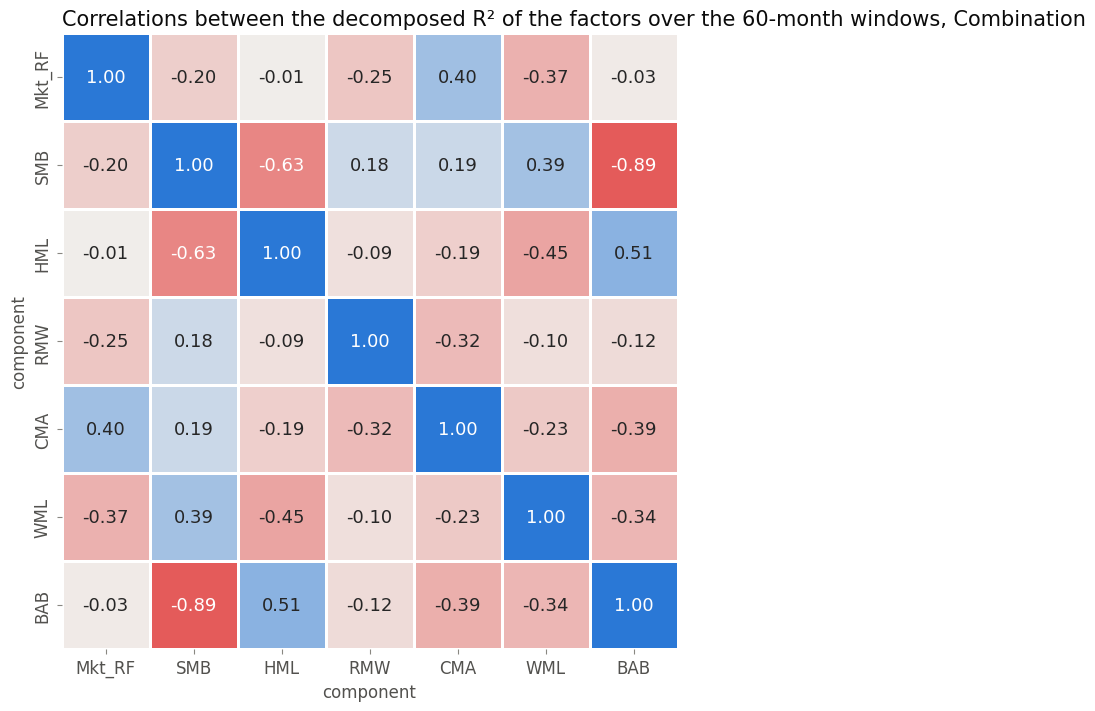

In [9]:
fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(combination[BRAZIL_FACTORS].corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1,
            square = True, cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_title('Correlations between the decomposed R² of the factors over the 60-month windows, Combination')
ax.grid(False)
plt.show()

The strongest link is between size and BAB: across the windows, when the share of one rises the share of the other falls, with a correlation of −0.89, as the second source of risk moved from BAB to size. Size and value also move against each other (−0.63). The share of the market barely moves with that of BAB (−0.03), unlike with the dollar-neutral BAB of the companion, which shared the risk of the market.

## How close the orthogonal factors stay to the originals

The resemblance $\text{diag}(\Psi)$ in each 60-month window.

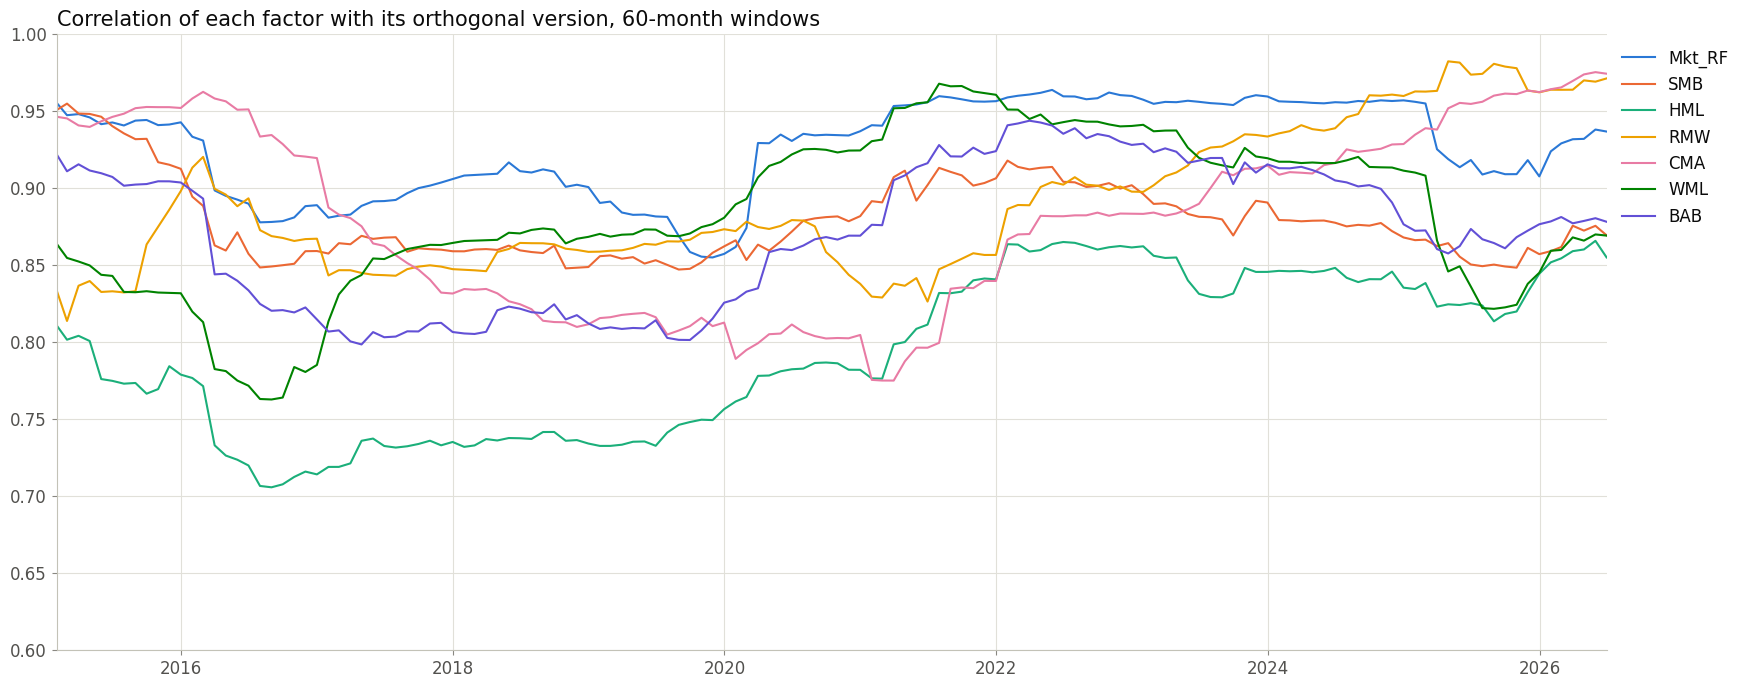

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
min,0.855,0.847,0.706,0.814,0.775,0.763,0.799
median,0.934,0.872,0.787,0.874,0.883,0.873,0.875
max,0.964,0.955,0.866,0.982,0.975,0.968,0.944


In [10]:
resemblance = {}
for end in range(60, len(factors) + 1):
    _, _, Psi = orthogonalize_swl(factors.iloc[end - 60:end], return_matrices = True)
    resemblance[factors.index[end - 1]] = np.diag(Psi)
resemblance = pd.DataFrame(resemblance, index = BRAZIL_FACTORS).T

fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(resemblance.index, resemblance[factor], color = colors[factor], label = factor)
ax.set_ylim(0.6, 1)
ax.margins(x = 0)
ax.set_title('Correlation of each factor with its orthogonal version, 60-month windows')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

resemblance.agg(['min', 'median', 'max']).round(3)

The orthogonal factors stay close to the originals in every window. The median resemblance goes from 0.79 (HML) to 0.93 (the market), and the lowest value of any factor in any window is 0.71, for HML. In most windows the resemblance is lower than over the full sample, because the factors are often more correlated within shorter periods.

In [11]:
rolling_monthly.round(4).to_csv('results/rolling_decomposition_60_months.csv')
yearly.round(4).to_csv('results/rolling_decomposition_252_days_by_year.csv')